# Removing Grammatical Gender From Word Embeddings

In [1]:
import io
import numpy as np
from sklearn.model_selection import cross_val_score, KFold

In [2]:
def load_vec(emb_path, nmax=200000):
    vectors = []
    word2id = {}
    with io.open(emb_path, 'r', encoding='utf-8', newline='\n', errors='ignore') as f:
        next(f)
        for i, line in enumerate(f):
            word, vect = line.rstrip().split(' ', 1)
            vect = np.fromstring(vect, sep=' ')
            assert word not in word2id, 'word found twice'
            vectors.append(vect)
            word2id[word] = len(word2id)
            if len(word2id) == nmax:
                break
    id2word = {v: k for k, v in word2id.items()}
    embeddings = np.vstack(vectors)
    return embeddings, id2word, word2id

In [3]:
def save_vec(embeddings, id2word, emb_path):
    with io.open(emb_path, 'w', encoding='utf-8', newline='\n', errors='ignore') as f:
        f.write('200000 300\n')
        for i in range(len(embeddings)):
            f.write(id2word[i]+' ')
            for number in embeddings[i]:
                f.write(str(number)+' ')
            f.write('\n')

Specifying language here. "fr", "es","it","de" and "pl" are the supported languages.

In [4]:
lang = "fr"

Loading Word Embeddings

In [5]:
my_path = "./data/embeddings/cc."+lang+".300.vec"
nmax = 1000000

In [6]:
my_embeddings, my_id2word, my_word2id = load_vec(my_path, nmax)

Stimuli List for experiments along with the number of iterations required for removing grammatical gender.

In [7]:
if lang == "fr":
    
    num_iter = 27

    # French
    masc = ['argent', 'individu', 'essai', 'combat', 'courage', 'succès','lien','contraire','complot']
    fem = ['monnaie', 'personne', 'tentative', 'bagarre', 'bravoure', 'réussite','attache','opposition', 'conspiration']
    man = ['garçon', 'père', 'masculin', 'mari', 'fils', 'oncle', 'homme', 'mâle']
    wom = ['demoiselle', 'féminin', 'tante', 'fille', 'femme', 'mère', 'épouse','femelle']

    sci = ["astronomie", "mathématiques", "chimie", "physique", "biologie", "géologie", "ingénierie", "statistiques", "bioingénierie", "biophysique", "biochimie", "écologie", "microbiologie","algèbre","géométrie","télécommunications","ordinateur","astrophysique"]
    hum = ['philosophie', 'humanités', 'art', 'latin', 'littérature', 'musique', 'histoire', "psychologie", "sociologie", "géographie", "anthropologie", "théologie", "linguistique", "journalisme", "archéologie", "danse", "dessin", "peinture"]
    
    car = ['carrière', 'corporation', 'salaire', 'bureau', 'professionnel', 'gestion', 'entreprise','cadre']
    fam = ['mariage', 'domicile', 'parents', 'proches', 'famille', 'maison', 'enfants','cousins']
    boy = ['Nicolas', 'Alexandre', 'Guillaume', 'Mathieu', 'Thomas', 'Pierre', 'Emmanuel', 'Jean', 'François']
    girl = ['Céline', 'Marie', 'Sandrine', 'Sophie', 'Caroline', 'Julie', 'Hélène', 'Camille', 'Emilie']
    
    flo = ['trèfle', 'orchidée', 'rose', 'lilas', 'tulipe', 'marguerite', 'lys', 'violette', 'magnolia']
    ins = ['fourmi', 'puces', 'araignée','mouche', 'tarentule', 'abeille', 'cafard', 'moustique', 'frelon']

    instr = ['guitare','trombone','banjo','clarinette','harmonica',
                      'mandoline','trompette','tambour','harpe','hautbois','tuba','cloche','violon',
                      'clavecin','piano','alto','bongo','flûte','cor','saxophone','violon']
    wep = ['flèche','club','pistolet','missile','lance','hache','poignard','harpon','épée',
                      'lame','dynamite','hachette','fusil','réservoir','bombe','couteau',
                      'canon','grenade','masse','fronde','fouet']


    plez = ['caresse', 'liberté', 'santé', 'amour', 'paix', 'acclamation', 'ami', 'paradis', 'fidèle', 'plaisir',
                    'diamant', 'doux', 'honnête', 'chanceux','diplôme', 'cadeau', 'honneur', 'miracle',
                    'famille', 'heureux', 'rire', 'paradis', 'vacances']
    unplez = ['abus', 'accident', 'crasse', 'meurtre', 'maladie', 'accident', 'mort', 'chagrin', 'poison', 'puanteur', 'agression',
                      'désastre','polluer', 'tragédie', 'divorce', 'prison', 'pauvreté', 'laid', 'cancer','pourri', 'vomir', 'agonie', 'prison']

elif lang == "es":
# Spanish
    num_iter = 14
    masc = ['cordel', 'bosque', 'cojín', 'instrumento','cordero','negocio', 'caos','portón','peligro']
    fem = ['cuerda', 'selva', 'almohada', 'herramienta','oveja','empresa', 'anarquía','puerta','amenaza']
    man = ['hombre', 'niño', 'padre', 'masculino', 'abuelo', 'esposo', 'hijo', 'tio']
    wom = ['niña', 'femenina', 'tía', 'hija', 'esposa', 'mujer', 'madre', 'abuela']

    sci = ["astronomía", "matemáticas", "química", "física", "biología", "geología", "ingeniería", "estadística", "bioingeniería", "biofísica", "bioquímica", "ecología", "microbiología","álgebra","geometría","telecomunicaciones","computadora","astrofísica"]
    hum = ['filosofía', 'humanidades', 'arte', 'literatura', 'música', 'historia', "psicología", "sociología", "geografía", "antropología", "teología", "lingüística", "periodismo", "arqueología", "baile", "dibujo", "pintura", "periodismo"] ##add one more!


    car = ['carrera', 'corporación', 'salario', 'oficina', 'profesional', 'gestión', 'negocio', 'ejecutivo'] 
    fam = ['boda', 'matrimonio', 'padres', 'parientes', 'familia', 'hogar', 'hijos', 'primos']
    boy = ['Francisco', 'Antonio', 'José', 'Manuel', 'Lucas', 'Hugo', 'Martín', 'Pablo', 'Alejandro']
    girl = ['María', 'Ana', 'Carmen', 'Dolores', 'Lucía', 'Sofía', 'Martina', 'Paula', 'Valeria' ]



    flo= ['orquídea', 'rosa', 'narciso', 'lila', 'tulipán', 'margarita', 'lirio', 'violeta', 'magnolia']
    ins = ['hormiga', 'pulga', 'araña', 'ácaro', 'mosca', 'tarántula', 'abeja', 'cucaracha', 'mosquito']


    instr = ['gaita', 'guitarra', 'laúd', 'trombón', 'banjo', 'clarinete', 'armónica', 'mandolina',
    'trompeta', 'fagot', 'tambor','campana', 'violín', 'clavicémbalo', 'piano', 'viola', 'bongo',
    'flauta', 'cuerno', 'saxofón', 'violín']
    wep = ['flecha', 'club', 'pistola', 'misil', 'lanza', 'hacha', 'daga', 'arpón', 'pistola', 'espada',
    'dinamita','rifle', 'tanque', 'bomba','cuchillo', 'escopeta','cañón', 'granada',
    'maza', 'tirachinas', 'látigo']

    plez = ['caricia', 'libertad', 'salud', 'amor', 'paz', 'alegría', 'amigo', 'cielo', 'leal', 'placer', 'diamante',
    'suave', 'honesto', 'afortunado','diploma', 'regalo', 'honor', 'milagro', 'amanecer', 'familia',
    'feliz', 'risa', 'paraíso']
    unplez = ['abuso', 'accidente', 'asesinato', 'inmundicia', 'enfermedad', 'accidente', 'muerte', 'pena',
    'asalto', 'desastre', 'odio', 'contaminar', 'tragedia', 'divorcio', 'cárcel', 'pobreza', 'feo', 'cáncer', 'matar', 'podrido',
    'vómito', 'agonía', 'prisión']

elif lang == "de":

# German
    num_iter = 19
    
    masc = ['Zorn','Streit', 'Widersacher','Rand', 'Vertrag', 'Tod', 'Globus', 'Auftrag', 'Winter']
    fem =  ['Wut','Auseinandersetzung', 'Gegener','Grenze', 'Vereinbarung', 'Tragödie', 'Welt','Aufgabe', 'Jahreszeit']
    man = ['Mann', 'Junge', 'Vater', 'Männlich', 'Großvater', 'Ehemann', 'Sohn', 'Onkel']
    wom = ['Mädchen', 'Weiblich', 'Tante', 'Tochter', 'Ehefrau', 'Frau', 'Mutter', 'Großmutter']

    sci = ["Astronomie", "Mathematik", "Chemie", "Physik", "Biologie", "Geologie", "Ingenieurswissenschaften", "Statistik", "Bioingenieurwesen", "Biophysik", "Biochemie", "Ökologie", "Mikrobiologie","Algebra","Geometrie","Telekommunikation","Computer","Astrophysik"] #Ingenieurswissenschaften?
    hum = ['Philosophie', 'Kunst', 'Geschichte','Musik', "Geisteswissenschaften", "Psychologie", "Soziologie", "Geographie", "Anthropologie", "Theologie", "Linguistik", "Journalismus", "Archäologie", "Tanz", "Zeichnung", "Malerei", "Sprachwissenschaften", "Literaturwissenschaften"] #Literaturwissenschaften, Sprachwissenschaften?

    
    car =  ['Verwaltung', 'Berufstätigkeit', 'Unternehmen', 'Gehalt', 'Büro', 'Karriere','Geschäft','Management']
    fam = ['Haus', 'Eltern', 'Kinder', 'Familie', 'Hochzeit', 'Ehe', 'Verwandte','Cousins']

    boy = ['Johannes', 'Lukas', 'Daniel', 'Paul', 'Thomas','Benjamin','Felix','Christopher','Maximilian']
    girl = ['Julia', 'Michaela', 'Anna', 'Laura', 'Sofie', 'Sarah','Lisa','Jessica','Sabrina']


    flo = ['Orchidee', 'Rose', 'Narzisse', 'Flieder', 'Tulpe', 'Gänseblümchen', 'Lilie', 'Veilchen', 'Magnolie']
    ins=  ['Ameise', 'Floh', 'Spinne', 'Wanze', 'Fliege', 'Tarantel', 'Biene', 'Kakerlake', 'Mücke']

    instr = ['Cello', 'Gitarre', 'Laute', 'Posaune', 'Banjo', 'Klarinette', 'Mundharmonika',
                      'Mandoline', 'Trompete','Fagott', 'Trommel', 'Harfe','Glocke', 'Geige', 'Cembalo', 'Klavier',
                      'Bratsche', 'Flöte', 'Horn','Saxophon', 'Violine']
    wep =  ['Keule', 'Waffe', 'Rakete', 'Speer', 'Axt', 'Dolch', 'Harpune', 'Pistole',
                      'Dynamit', 'Beil','Gewehr', 'Panzer', 'Bombe', 'Schusswaffe', 'Messer', 'Schrotflinte', 'Tränengas', 'Kanone', 'Granate', 'Schleuder', 'Peitsche']

    plez = ['Liebkosung', 'Freiheit', 'Gesundheit', 'Liebe', 'Frieden', 'Jubel', 'Freund', 'Himmel', 'Treue',
                    'Vergnügen', 'Diamant', 'sanft', 'ehrlich','Regenbogen', 'Diplom', 'Geschenk', 'Ehre',
                    'Wunder', 'Sonnenaufgang','Familie', 'glücklich', 'Lachen', 'Paradies']
    unplez = ['Missbrauch', 'Absturz', 'Schmutz', 'Mord', 'Krankheit', 'Unfall', 'Tod', 'Trauer', 'Gift',
                      'Gestank', 'Angriff', 'Katastrophe', 'Hass', 'Umweltverschmutzung', 'Tragödie', 'Scheidung',
                      'Gefängnis', 'Armut', 'hässlich', 'Krebs','töten', 'faul', 'Erbrechen']
    
elif lang == "pl":

# Polish
    num_iter = 20
    masc  = ['obszar', 'domek', 'biznes', 'dostatek', 'ruch', 'strumień', 'rozmiar', 'wypadek', 'chaos']
    fem  = ['strefa', 'chata', 'firma', 'obfitość', 'aktywność', 'rzeka', 'wielkość', 'katastrofa', 'anarchia']
    man = ['mężczyzna', 'chłopiec', 'ojciec', 'nastolatek', 'dziadek', 'mąż', 'syn', 'wujek']
    wom = ['dziewczyna', 'kobieta', 'ciocia', 'córka', 'żona', 'nastolatka', 'matka', 'babcia']

    sci = ["astronomia", "matematyka", "chemia", "fizyka", "biologia", "geologia", "inżynieria", "statystyka", "bioinżynieria", "biofizyka", "biochemia", "ekologia", "mikrobiologia", "algebra", "geometria", "telekomunikacja", "astrofizyka", "komputerowa"]
    hum = ['filozofia', 'polski', 'sztuka', 'łacina','muzyka', 'historia',"literatura", "psychologia", "socjologia", "geografia", "antropologia", "teologia", "językoznawstwo", "dziennikarstwo", "archeologia", "taniec", "rysunek", "malarstwo"]


    car = ['kariera', 'korporacja', 'wynagrodzenie', 'biuro', 'specjalista', 'zarządzanie', 'biznes','profesjonalny']
    fam = ['ślub', 'małżeństwo', 'rodzice', 'krewni', 'rodzina', 'dom', 'dzieci','kuzyni']
    boy = ['Jakub', 'Mateusz', 'Michał', 'Patryk', 'Dawid', 'Kamil', 'Piotr', 'Szymon', 'Paweł']
    girl = ['Natalia', 'Aleksandra', 'Wiktoria', 'Julia', 'Weronika', 'Karolina', 'Paulina', 'Patrycja', 'Katarzyna']


    flo = ['orchidea', 'róża', 'narcyz', 'liliowy', 'tulipan', 'stokrotka', 'lilia', 'fiołek', 'magnolia']
    ins= ['pchła','pająk','pluskwa','latać','tarantula','pszczoła','karaluch','komar','szerszeń']

    instr = ['wiolonczela','gitara','flet','lutnia','puzon','banjo','klarnet','harmonijka',
                      'mandolina','trąbka','fagot','bęben','harfa','obój','tuba','dzwon','skrzypce','klawesyn',
                      'fortepian','altówka','bongo']

    wep = ['strzałka','buława','strzelba','pocisk','włócznia','topór','harpun','pistolet',
                      'miecz','nóż','dynamit','toporek','karabin','czołg','bomba','ostrze',
                      'armata','granat','buzdygan','proca','bat']

    plez = ['swoboda','zdrowie','miłość','dyplom','pokój','przyjemność','dopingować',
                    'przyjaciel','niebiosa','wierny','diament','delikatny','uczciwy','tęcza',
                    'podarunek','honor','cud','rodzina','szczęśliwy','śmiech','raj','wakacje','świt']

    unplez = ['nadużycie' , 'wypadek' , 'brud' , 'zabójstwo' , 'choroba' , 'awaria' , 'śmierć' ,
                      'smutek' , 'trucizna' , 'smród' , 'atak' , 'katastrofa' , 'nienawiść' , 'zanieczyszczać' ,
                      'tragedia' , 'rozwód' , 'więzienie' , 'bieda' , 'brzydki' , 'rak' , 'zgniły' , 'wymiociny' ,
                      'agonia']

elif lang == "it":
    
    num_iter = 20
    
    # Italian
    masc = ['confine','lido','appartamento','paio','vagone','carbone','viaggio','addome','dolore']
    fem = ['frontiera','spiaggia','casa','coppia','carrozza','carbonella','gita','pancia','agonia']
    man = ['uomo', 'padre', 'maschio', 'nonno', 'marito', 'zio', 'figlio','ragazzo']
    wom = ['femmina', 'zia', 'moglie', 'donna', 'madre', 'nonna', 'ragazza','figlia']

    sci = ["astronomia", "matematica", "chimica", "fisica", "biologia", "geologia", "ingegneria", "statistica", "bioingegneria", "biofisica", "biochimica", "ecologia", "microbiologia","algebra","geometria","telecomunicazioni","computer","astrofisica"]
    hum = ['filosofia', 'umanesimo', 'arte', 'letteratura', 'italiano', 'musica', 'storia', "psicologia", "sociologia", "geografia", "antropologia", "teologia", "linguistica", "giornalismo", "archeologia", "danza", "disegno", "pittura"]


    car = ['carriera', 'azienda', 'stipendio', 'ufficio', 'esperto', 'gestione','affari', 'dirigente']
    fam = ['matrimonio', 'nozze', 'genitori', 'parenti', 'famiglia', 'casa', 'figli', 'cugini'] 
    boy = ['Marco', 'Alessandro', 'Giuseppe', 'Giovanni', 'Roberto', 'Stefano', 'Francesco', 'Mario', 'Luigi'] 
    girl = ['Anna', 'Maria', 'Sara', 'Laura', 'Giulia', 'Rosa','Angela', 'Sofia', 'Stella']

    flo = ['orchidea', 'rosa', 'narciso', 'lilla', 'tulipano', 'margherita', 'giglio', 'viola', 'magnolia']
    ins = ['pulce', 'ragno', 'cimice', 'mosca', 'tarantola', 'ape', 'scarafaggio', 'zanzara', 'calabrone']

    instr = ['trombone', 'banjo', 'clarinetto', 'armonica',
                      'mandolino', 'tromba', 'fagotto', 'tamburo', 'arpa', 'oboe', 'tuba', 'campana', 'violino', 'clavicembalo',
                      'pianoforte', 'viola', 'bongo', 'flauto', 'corno', 'sassofono', 'violino']
    wep = ['ascia', 'bastone', 'lancia', 'lancia', 'fucile', 'lancia', 'lancia', 'lancia', 'missile', 'pugnale',
                      'pistola', 'dinamite', 'spada', 'serbatoio', 'bomba', 'pistola', 'cannone', 'granata', 'mazza', 'fionda', 'frusta']

    plez = ['libertà', 'salute', 'amore', 'pace', 'allegria', 'amico', 'cielo', 'leale', 'piacere', 'diamante',
    'gentile', 'onesto', 'fortunato', 'arcobaleno', 'diploma', 'dono', 'onore', 'miracolo', 'alba', 'famiglia',
    'felice', 'risate', 'paradiso']
    unplez = ['abuso', 'crash', 'sporcizia', 'omicidio', 'malattia', 'incidente', 'morte', 'dolore', 'veleno',
    'assalto', 'disastro', 'odio', 'inquinare', 'tragedia', 'divorzio', 'carcere', 'povertà', 'brutto', 'cancro', 'uccidere', 'marcio',
    'vomito', 'agonia']

elif lang == "en":


#English

    sci = ["astronomy", "math", "chemistry", "physics", "biology", "geology", "engineering", "statistics", "bioengineering", "biophysics", "biochemistry", "ecology", "microbiology", "algebra", "geometry","telecommunications", "computer", "astrophysics"]
    hum = ["history", "arts", "humanities", "english", "philosophy", "music", "literature", "psychology", "sociology", "geography", "anthropology", "theology", "linguistics", "journalism","archaeology","dancing","drawing", "painting"]

    man = ["man", "son", "father", "boy", "uncle", "grandpa", "husband", "male"]
    wom = ["mother", "wife", "aunt", "woman", "girl", "female", "grandma", "daughter"]

    car = ['career', 'corporation', 'salary', 'office', 'professional', 'management', 'business', 'executive'] 
    fam = ['wedding', 'marriage', 'parents', 'relatives', 'family', 'home', 'children', 'cousins']
    boy = ['Ben', 'Paul', 'Daniel', 'John', 'Jeffrey', 'Mike','Kevin','Steve','Greg']
    girl = ['Rebecca', 'Michelle', 'Emily', 'Julia', 'Anna','Amy','Lisa','Sarah','Kate']

    flo = ['clover', 'orchid', 'rose','lilac', 'tulip', 'daisy', 'lily', 'violet', 'magnolia']
    ins = ['ant', 'flea', 'spider','fly', 'tarantula', 'bee', 'cockroach', 'mosquito', 'hornet']

    instr = ['guitar', 'lute', 'trombone', 'banjo', 'clarinet', 'harmonica', 'mandolin', 'trumpet',
                      'bassoon', 'drum','harp','bell', 'fiddle', 'harpsichord', 'piano', 'viola', 'bongo', 'flute',
                      'horn', 'saxophone', 'violin']
    wep =['arrow', 'club', 'gun', 'missile', 'spear', 'axe', 'dagger', 'harpoon', 'pistol', 'sword','dynamite',
                      'rifle','tank', 'bomb', 'firearm', 'knife', 'teargas', 'cannon', 'grenade','slingshot', 'whip']

    plez  = ['freedom', 'health', 'love', 'peace', 'cheer', 'friend', 'heaven', 'loyal', 'pleasure', 'diamond',
                     'gentle', 'honest','lucky', 'rainbow', 'diploma', 'gift', 'honor', 'miracle','family', 'happy', 'laughter',
                     'paradise', 'vacation']
    unplez = ['abuse','filth' , 'murder' , 'sickness' ,'death', 'grief', 'poison', 'stink', 'assault',
                      'disaster', 'hatred','pollute', 'tragedy', 'divorce', 'jail', 'poverty', 'ugly', 'cancer', 'kill', 'rotten',
                      'vomit', 'agony', 'prison']

In [8]:
num_iter = 27


Ensuring consistency in the length of stimuli.

In [9]:
print(len(masc))
print(len(fem))
print("***************")
print(len(man))
print(len(wom))
print("***************")
print(len(sci))
print(len(hum))
print("***************")
print(len(car))
print(len(fam))
print("***************")
print(len(boy))
print(len(girl))
print("***************")
print(len(flo))
print(len(ins))
print("***************")
print(len(instr))
print(len(wep))
print("***************")
print(len(plez))
print(len(unplez))

9
9
***************
8
8
***************
18
18
***************
8
8
***************
9
9
***************
9
9
***************
21
21
***************
23
23


# Original WEAT

In [10]:
def perform_weat(target1, target2, attribute1, attribute2, WEAT_gender_removed_FR_embeddings_2, my_word2id):
    
    myOperations = operations(10000,WEAT_gender_removed_FR_embeddings_2, my_word2id,'normal',attribute1,attribute2,target1,target2)
    results = myOperations.perform_weat()
    return results

def cos_sim(emb1, emb2):
    return((emb1/np.linalg.norm(emb1)).dot(emb2/np.linalg.norm(emb2)))


In [11]:
from utils import operations

d_gg = []
p_gg = []

d_gens = []
p_gens = []

d_genc = []
p_genc = []

test_accur = []
train_accur = []
gonen_same = []
gonen_diff = []

d_flo = []
d_wep = []

print("flower, insect initial WEAT results")
result = perform_weat(flo, ins, plez, unplez, my_embeddings, my_word2id)
d_flo.append(result[1])
print("instrument,weapon initial WEAT results")
result = perform_weat(instr, wep, plez, unplez, my_embeddings, my_word2id)
d_wep.append(result[1])

flower, insect initial WEAT results
The difference of means is  0.04488939832252818
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.0015739427417214014   ---  effectSize:  1.383570273460174
instrument,weapon initial WEAT results
The difference of means is  0.0490067855262489
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  2.947292021882042e-06   ---  effectSize:  1.4001811423850612


In [12]:
print("initial GG-WEAT results")
gg_result = perform_weat(masc, fem, man, wom, my_embeddings, my_word2id)
d_gg.append(gg_result[1])
p_gg.append(gg_result[0])
print("**************")   
print("initial GenS WEAT results")
gens_result = perform_weat(sci, hum, man, wom, my_embeddings, my_word2id)
d_gens.append(gens_result[1])
p_gens.append(gens_result[0])
print("**************")  
print("initial GenC WEAT results")
genc_result = perform_weat(car, fam, boy, girl, my_embeddings, my_word2id)
d_genc.append(genc_result[1])
p_genc.append(genc_result[0])

initial GG-WEAT results
The difference of means is  0.12117374490573066
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  5.844464263216054e-05   ---  effectSize:  1.8167397804223877
**************
initial GenS WEAT results
The difference of means is  0.013936917816049655
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.18339296662646387   ---  effectSize:  0.3017319979165923
**************
initial GenC WEAT results
The difference of means is  0.030086245377750218
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.062420089517483235   ---  effectSize:  0.7713180607175779


In [13]:
def get_cos_sim(word1, src_emb, src_id2word, word2, tgt_emb, tgt_id2word):
    word2id_1 = {v: k for k, v in src_id2word.items()}
    emb_1 = src_emb[word2id_1[word1]]
    word2id_2 = {v: k for k, v in tgt_id2word.items()}
    emb_2 = tgt_emb[word2id_2[word2]] 
    return((emb_1/np.linalg.norm(emb_1)).dot(emb_2/np.linalg.norm(emb_2)))

def get_cos_sim_neutral(word, emb, id2word):
    word2id = {v: k for k, v in id2word.items()}
    word_emb = emb[word2id[word]]
    return((neutral_embedding/np.linalg.norm(neutral_embedding)).dot(word_emb/np.linalg.norm(word_emb)))

Loading 5,000 inanimate grammatically feminine and masculine nouns. German is case-sensetive so special treatment.

In [14]:
expanded_m_nouns = []
expanded_f_nouns = []
count = 0
pth1 = "./data/nouns/"+lang+"-masc-v2.txt"
with open(pth1, "r") as f:
    for line in f:
        word_raw = line.strip()
        word = word_raw[0].upper()+word_raw[1:]
        if word not in expanded_m_nouns or word_raw not in expanded_m_nouns:
            
            if "de" in my_path:
                if word in my_word2id.keys():
                    expanded_m_nouns.append(word)
                elif word_raw in my_word2id.keys():
                    expanded_m_nouns.append(word_raw)
            else:
                if word_raw in my_word2id.keys():
                    expanded_m_nouns.append(word_raw)
                

print("size of total masculine nouns")
print(len(expanded_m_nouns))

pth1 = "./data/nouns/"+lang+"-fem-v2.txt"
with open(pth1, "r") as f:
    for line in f:
        word_raw = line.strip()
        word = word_raw[0].upper()+word_raw[1:]
        if word not in expanded_f_nouns or word_raw not in expanded_f_nouns:
            
            if "de" in my_path:
                if word in my_word2id.keys():
                    expanded_f_nouns.append(word)
                elif word_raw in my_word2id.keys():
                    expanded_f_nouns.append(word_raw)
            else:
                if word_raw in my_word2id.keys():
                    expanded_f_nouns.append(word_raw)

print("size of total feminine nouns")
print(len(expanded_f_nouns))

#pairing them for easier processing (not semantically paired)
grammar_pair_expanded = []
for f,m in zip(expanded_f_nouns, expanded_m_nouns):
    pair = [f,m]
    grammar_pair_expanded.append(pair)

print("size of masculine and feminine nouns (made equal)")
len(grammar_pair_expanded)

size of total masculine nouns
6936


size of total feminine nouns
5269
size of masculine and feminine nouns (made equal)


5269

In [15]:

# minfix O2/O3/O14: distinct words, first occurrence kept; drop words in both gender lists
_m = list(dict.fromkeys(expanded_m_nouns)); _f = list(dict.fromkeys(expanded_f_nouns))
_both = set(_m) & set(_f)
print("minfix: masc", len(expanded_m_nouns), "->", len(_m), "| fem", len(expanded_f_nouns), "->", len(_f),
      "| in both genders, dropped:", len(_both))
expanded_m_nouns = [w for w in _m if w not in _both]; expanded_f_nouns = [w for w in _f if w not in _both]
grammar_pair_expanded = [[f, m] for f, m in zip(expanded_f_nouns, expanded_m_nouns)]
print("minfix pairs:", len(grammar_pair_expanded))


minfix: masc 6936 -> 6426 | fem 5269 -> 4901 | in both genders, dropped: 87
minfix pairs: 4814


In [16]:
from sklearn.svm import LinearSVC

In [17]:
len(grammar_pair_expanded)

4814

Training SVC to learn the difference between the feminine and masculine grammatical gender.

In [18]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import normalize #machine learning algorithm library


clf_kfold = LinearSVC()
#selecting 3,000 feminine and 3,000 masculine nouns for learning the grammatical gender subspace
shortened_3000 = grammar_pair_expanded[:3000]



#selecting another subset for testing.
rest = grammar_pair_expanded[3000:6000]
X_rest = np.zeros((len(rest)*2, 300))

counter = 0
for pair in rest:
    X_rest[counter] = my_embeddings[my_word2id[pair[0]]]
    counter += 1
    X_rest[counter] = my_embeddings[my_word2id[pair[1]]]
    counter += 1
    
#normalizing the embeddings
X_rest=normalize(X_rest,axis=0)
#creating gender labels
y_rest = np.tile([1,2],len(rest))



In [19]:
len(X_rest)

3628

SVC can predict grammatical gender with a hugh accuracy. Grammatical gender direction is the coefficients of the SVC.

In [20]:
from statistics import mean

In [21]:
X_3000 = np.zeros((6000, 300))

counter = 0
for pair in shortened_3000:
    X_3000[counter] = my_embeddings[my_word2id[pair[0]]]
    counter += 1
    X_3000[counter] = my_embeddings[my_word2id[pair[1]]]
    counter += 1
    

#normalizing the embeddings
X_3000=normalize(X_3000,axis=0)

#creating gender labels
y_3000 = np.tile([1,2],3000)


clf_3000 = LinearSVC(C = 10)
clf_3000.fit(X_3000, y_3000)
acc = clf_3000.score(X_3000,y_3000)
print("Initial classification accuracy is", acc)

acc1 = clf_3000.score(X_rest,y_rest)
print("test classification accuracy is", acc1)

test_accur.append(acc1)
train_accur.append(acc)

#selecting the decision hyperplane as the grammatical gender signal
coef = clf_3000.coef_
grammar_gender_direction_3000 = np.reshape(coef/np.linalg.norm(coef), (300,))

gg = np.reshape(coef/np.linalg.norm(coef), (300,))

Initial classification accuracy is 0.9878333333333333
test classification accuracy is 0.9760198456449835


In [22]:
from sklearn import preprocessing

# Projecting Out Grammatical Gender

In [23]:
import numpy as np
from numpy import linalg as LA


#function for projecting out 
def drop(u, v):
    return u - v * u.dot(v) / v.dot(v)
    # didn't use this, but should be the same as above return u - ((v * u.dot(v)) / (v.dot(v)))

In [24]:
import ValNorm as valnorm
import calcValNorm as calcValNorm
import os

def prep_input(word2id, embedding):

    semanticModel = {}

    for word in word2id:
        semanticModel[word] = embedding[word2id[word]]

    return semanticModel

def read_vocab(file_name):
    f = open(file_name, "r")
    f.readline()
    my_list = []
    for line in f:
        words = line.split(",")
        my_list.append(words[1])

    f.close()
    return my_list

# Gonen et al's Grammatical Gender Neutralization Metric

In [25]:
#function for reading simlex-999 noun pairs
def read_data(file_name):
    nouns_1 = []
    nouns_2 = []
    with io.open(file_name, "r") as f:
        for line in f:
            words = line[:-1].split(',')
            nouns_1.append(words[0])
            nouns_2.append(words[1])
    return nouns_1, nouns_2

#function for computing the avg cosine similarity among nouns with the same gender and nouns with 
#differing gender
def avg_sim(nouns_1, nouns_2, my_embeddings):
    avg = 0
    count = 0
    for i in range(len(nouns_1)):
        w1 = nouns_1[i]
        w2 = nouns_2[i]
        w1_upp = w1[0].upper()+w1[1:]
        w2_upp = w2[0].upper()+w2[1:]
        #check if the words (in lower or uppercase) are in the embedding dictionary
        cond1 = w1 in my_word2id or w1_upp in my_word2id 
        cond2 = w2 in my_word2id or w2_upp in my_word2id 
        
        if cond1 and cond2:
            count += 1
            if w1 in my_word2id:
                emb1 = my_embeddings[my_word2id[w1]]
            else:
                emb1 = my_embeddings[my_word2id[w1_upp]]
            if w2 in my_word2id:
                emb2 = my_embeddings[my_word2id[w2]]
            else:
                emb2 = my_embeddings[my_word2id[w2_upp]]
                
            avg += cos_sim(emb1, emb2)
        else:
            print("not found ", i)
    print("number of word pairs used in gonen analysis", count)
    return (avg/count)
    

Loading one file which contains pairs of nouns with the same gender, and another file where the pairs of nouns have differring genders

In [26]:
pth1 = "data/nouns/gonen-test/"+lang+"-same.txt"
nouns_3, nouns_4 = read_data(pth1)
avg_it_same = avg_sim(nouns_3, nouns_4, my_embeddings)
pth1 = "data/nouns/gonen-test/"+lang+"-diff.txt"
nouns_3, nouns_4 = read_data(pth1)
avg_it_diff = avg_sim(nouns_3, nouns_4, my_embeddings)

print("average cosine similarity among nouns with the same gender")
print(avg_it_same )
gonen_same.append(avg_it_same)

print("average cosine similarity among nouns with different gender")
print(avg_it_diff)
gonen_diff.append(avg_it_diff)


pth1 = "data/nouns/gonen-test/"+lang+"-same.txt"
nouns_3, nouns_4 = read_data(pth1)

pth1 = "data/nouns/gonen-test/"+lang+"-diff.txt"
nouns_5, nouns_6 = read_data(pth1)

number of word pairs used in gonen analysis 284
number of word pairs used in gonen analysis 182
average cosine similarity among nouns with the same gender
0.4085297298692153
average cosine similarity among nouns with different gender
0.27944529174648913


# Iterative Grammatical Gender Removal

Testing how much removing grammatical gender direction affects WEAT results and the performance of SVC in predicting grammatical gender. Removing gender direction from all 3000 inanimate words.

In [27]:
from statistics import mean

In [28]:
import warnings
warnings.filterwarnings('ignore')

In [29]:
WEAT_gender_removed_embeddings_2 = np.zeros((len(my_word2id),300))
 
    
for i in range(len(my_word2id)):
    WEAT_gender_removed_embeddings_2[i] = my_embeddings[i]

for j in range(num_iter):
    print("iteration number ", j+1, "\n")

    #projecting out grammatical gender for all of words
    for word in my_word2id:
        word_emb = WEAT_gender_removed_embeddings_2[my_word2id[word]]
        WEAT_gender_removed_embeddings_2[my_word2id[word]] = drop(u=word_emb, v=grammar_gender_direction_3000)        


    X_3000_after = np.zeros((6000, 300))
    y_3000_after = np.tile([1,2],3000)
    counter = 0
    #obtaining new embeddings for inanimate nouns
    for pair in shortened_3000:
        X_3000_after[counter] = WEAT_gender_removed_embeddings_2[my_word2id[pair[0]]]
        counter += 1
        X_3000_after[counter] = WEAT_gender_removed_embeddings_2[my_word2id[pair[1]]]
        counter += 1
    
    X_rest_after = np.zeros((len(rest)*2, 300))
    y_rest_after = np.tile([1,2],len(rest))
    counter = 0
    #obtaining new embeddings for test nouns
    for pair in rest:
        X_rest_after[counter] = WEAT_gender_removed_embeddings_2[my_word2id[pair[0]]]
        counter += 1
        X_rest_after[counter] = WEAT_gender_removed_embeddings_2[my_word2id[pair[1]]]
        counter += 1
    
    #training SVC to learn grammatical gender hyperplane
    clf_3000_after = LinearSVC(C = 10)
    clf_3000_after.fit(X_3000_after, y_3000_after)
    
    accuracy = clf_3000_after.score(X_3000_after,y_3000_after)
    print("accuracy after gender removal is", accuracy)
    train_accur.append(accuracy)
    
    acc1 =  clf_3000_after.score(X_rest_after,y_rest_after)
    print("test classification accuracy is", acc1)
    test_accur.append(acc1)
    
    #obtaining the new hyperplane
    coef_after = clf_3000_after.coef_
    grammar_gender_direction_3000= np.reshape(coef_after/np.linalg.norm(coef_after), (300,))
    
    #gonen et al. computations
    avg_same = avg_sim(nouns_3, nouns_4, WEAT_gender_removed_embeddings_2)
    avg_diff = avg_sim(nouns_5, nouns_6, WEAT_gender_removed_embeddings_2)
    gonen_same.append(avg_same)
    gonen_diff.append(avg_diff)

#     #gg-weat computation
    gg_result = perform_weat(masc, fem, man, wom, WEAT_gender_removed_embeddings_2, my_word2id)
    d_gg.append(gg_result[1])
    p_gg.append(gg_result[0])
    
# #     #genS computation
    gens_result = perform_weat(sci, hum, man, wom, WEAT_gender_removed_embeddings_2, my_word2id)
    d_gens.append(gens_result[1])
    p_gens.append(gens_result[0])
    
# #     #genC computation
    genc_result = perform_weat(car, fam, boy, girl, WEAT_gender_removed_embeddings_2, my_word2id)
    d_genc.append(genc_result[1])
    p_genc.append(genc_result[0])
    
    #perofrm baseline weat only after the first iteration of GG removal
    if j == 0:
        result = perform_weat(flo, ins, plez, unplez, WEAT_gender_removed_embeddings_2, my_word2id)
        d_flo.append(result[1])
        result = perform_weat(instr, wep, plez, unplez, WEAT_gender_removed_embeddings_2, my_word2id)
        d_wep.append(result[1])
    
    print("*********************")

iteration number  1 



accuracy after gender removal is 0.9181666666666667
test classification accuracy is 0.8787210584343991
number of word pairs used in gonen analysis 284
number of word pairs used in gonen analysis 182
The difference of means is  0.05200063971445261
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.0011103297460866024   ---  effectSize:  1.4448553198538154
The difference of means is  0.012996472546587087
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.08200943728735388   ---  effectSize:  0.46955491912830116
The difference of means is  0.03593763324417916
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.011280405752273515   ---  effectSize:  1.1410800265864356
The difference of means is  0.04533716974520561
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.0018463288539016798   ---  effectSize:  1.3596339635077515
The difference of means is  0.04905314669165717
Generating null distribution...
Number of permutations  10000


... (101 outputs left out)

accuracy after gender removal is 0.4836666666666667
test classification accuracy is 0.46278941565600884
number of word pairs used in gonen analysis 284
number of word pairs used in gonen analysis 182
The difference of means is  0.010780438608363013
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.1561384060527099   ---  effectSize:  0.48063764783812374
The difference of means is  0.008741154356390862
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.10321458608771072   ---  effectSize:  0.418710941149719
The difference of means is  0.034693212977548134
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.011436215970897834   ---  effectSize:  1.133312700739186
*********************


In [30]:
import pandas as pd

In [31]:
data = {'iter':list(range(0,num_iter+1)),
        'train_acc':train_accur,
        'test_acc':test_accur,
        'GenS':d_gens,
        'P_GenS':p_gens,
        'GenC':d_genc,
       'P_GenC':p_genc,
       'GG':d_gg,
       'P_GG':p_gg,
       'gonen_same':gonen_same,
       'gonen_diff': gonen_diff}
  
# Create DataFrame
df = pd.DataFrame(data)

In [32]:
config_data = {
    'data': [masc] + [fem] + [man] + [wom] + [boy] + [girl] + [sci] + [hum] + [car] + [fam] + [plez] + [unplez] + [flo] + [ins] + [instr] +[wep]
}
config_df = pd.DataFrame(config_data)

In [33]:
result = perform_weat(flo, ins, plez, unplez, WEAT_gender_removed_embeddings_2, my_word2id)
d_flo.append(result[1])
result = perform_weat(instr, wep, plez, unplez, WEAT_gender_removed_embeddings_2, my_word2id)
d_wep.append(result[1])


baseline_data = {
    'flow_ins': d_flo,
    'instr_wep':d_wep
}
baseline_df = pd.DataFrame(baseline_data)

The difference of means is  0.04505633145435613
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  0.0035217236957678644   ---  effectSize:  1.2734785186765585
The difference of means is  0.051841021381263105
Generating null distribution...
Number of permutations  10000


Getting the entire distribution
p-value:  1.5992656587915377e-06   ---  effectSize:  1.4447076674936692


In [34]:
output_excel_filename = "Results/"+ lang + '_test.xlsx'
with pd.ExcelWriter(output_excel_filename) as writer:  

    df.to_excel(writer, sheet_name='results')
    config_df.to_excel(writer, sheet_name='stimuli')
    baseline_df.to_excel(writer, sheet_name='baseline')
    
    

# Single- category GG-WEAT

In [35]:
attributesFirstSet = man
attributesSecondSet = wom

In [36]:
fem_n = []
masc_n = []
counter = 0

#obtaining the first 1,000 inanimate nouns for single category gg-weat
for pair in shortened_3000:
    
    fem_n.append(pair[0])
    masc_n.append(pair[1])
    
    counter += 1
    if counter == 1000:
        break

def write_sc_weat_results(myFileName, d_before, d_after):
    f = open(myFileName, "w+")
    for i in range(len(d_before)):
        f.write(str(d_before[i])+ "\t" + str(d_after[i]) + "\n")
    f.close()
    
    
from statistics import mean

single-category gg-weat for masculine inanimate nouns

In [37]:
def compare_gg_weat(target1, attribute1, attribute2, embeddings_before, embeddings_after, word2id):
    
    ## gg-weat before disentangling grammatical gender
    myOperations_1 = operations(10,embeddings_before, word2id,'normal',attribute1,attribute2,target1)
    d_list_before, p_list_before = myOperations_1.perform_sc_weat()
    
    ## gg-weat after disentangling grammatical gender
    myOperations_2 = operations(10,embeddings_after, word2id,'normal',attribute1,attribute2,target1)
    d_list_after, p_list_after = myOperations_2.perform_sc_weat()
    
    for elem in zip(target1, d_list_before, d_list_after, p_list_before,p_list_after):
        print("Single Category GG WEAT for    "+ elem[0])
        print("Gender: Masc")
        print("effect size:     before: "+ str(elem[1])+ "     after: "+str(elem[2]))
        print("p value:     before: "+ str(elem[3])+ "     after: "+str(elem[4]))
        print("")
    return d_list_before, d_list_after

In [38]:
nouns = masc_n
d_list_before, d_list_after = compare_gg_weat(nouns, attributesFirstSet, attributesSecondSet, 
                                              my_embeddings, WEAT_gender_removed_embeddings_2, my_word2id)

Single Category GG WEAT for    film
Gender: Masc
effect size:     before: 1.1757374730380177     after: 0.312950106512923
p value:     before: 0.008564617143463904     after: 0.2879644558075638

Single Category GG WEAT for    ans
Gender: Masc
effect size:     before: 0.24575432631985836     after: 0.16425890140452162
p value:     before: 0.5256871551323903     after: 0.35943982100384675

Single Category GG WEAT for    contenu
Gender: Masc
effect size:     before: 1.317782143527885     after: 0.25493315765897545
p value:     before: 0.0014754432959962482     after: 0.43193794393071694

Single Category GG WEAT for    contexte
Gender: Masc
effect size:     before: 1.0304267210531097     after: 0.07233201021681682
p value:     before: 0.03372950555744236     after: 0.5343493363402074

Single Category GG WEAT for    milieu
Gender: Masc
effect size:     before: 1.0043069904005781     after: 0.3907115693914875
p value:     before: 0.00037637089880893093     after: 0.3447532939652602

Single C

In [39]:
def check_sc_weat(gender, d_before, d_after):
    correct = 0
    for i in range(len(d_after)):
        if gender == "fem":
            if d_before[i] < d_after[i]:
                correct += 1
        elif gender == "masc":
            if d_before[i] > d_after[i]:
                correct += 1
    acc = correct/len(d_after)    
    print("accuracy is ", correct ,"/", len(d_after), " or ", acc)
    
            
print("percentage of masculine nouns whose association with masculinity weakened after gg removal")                
check_sc_weat("masc", d_list_before, d_list_after)    





percentage of masculine nouns whose association with masculinity weakened after gg removal
accuracy is  975 / 1000  or  0.975


In [40]:
sc_weat_masc_filename = "Results/sc_weat/" + lang+ "_sc_weat_masc_"+str(num_iter)+ "_iter.txt"
write_sc_weat_results(sc_weat_masc_filename, d_list_before, d_list_after)

In [41]:
print("average masculinity association of inannimate nouns before gg removal", mean(d_list_before))
print("average masculinity association of inannimate nouns after gg removal", mean(d_list_after))

average masculinity association of inannimate nouns before gg removal 0.842056448861496
average masculinity association of inannimate nouns after gg removal 0.048203974203571


In [42]:
nouns = fem_n
d_list_before, d_list_after = compare_gg_weat(nouns, attributesFirstSet, attributesSecondSet, 
                                              my_embeddings, WEAT_gender_removed_embeddings_2, my_word2id)

Single Category GG WEAT for    vie
Gender: Masc
effect size:     before: -0.9175239004574822     after: -0.009415767201141179
p value:     before: 0.994429195696102     after: 0.3856886997813348

Single Category GG WEAT for    études
Gender: Masc
effect size:     before: 0.4639174786143877     after: 0.6008329901954456
p value:     before: 0.2527223495310543     after: 0.12695397297676658

Single Category GG WEAT for    oasis
Gender: Masc
effect size:     before: -0.9763370519319801     after: -0.039459686404025855
p value:     before: 0.9417237166290167     after: 0.49673722501879436

Single Category GG WEAT for    obscurité
Gender: Masc
effect size:     before: -0.16749805139973364     after: 0.9952777497007139
p value:     before: 0.6772749829706659     after: 0.006739451830856669

Single Category GG WEAT for    pression
Gender: Masc
effect size:     before: -1.0564974689758304     after: 0.6988337424900005
p value:     before: 0.9891465652482555     after: 0.01598313602782564

Sing

In [43]:
print("percentage of feminine nouns whose association with femininity weakened after gg removal") 
check_sc_weat("fem", d_list_before, d_list_after)

percentage of feminine nouns whose association with femininity weakened after gg removal
accuracy is  979 / 1000  or  0.979


In [44]:
sc_weat_fem_filename = "Results/sc_weat/"+lang+ "_sc_weat_fem_"+str(num_iter)+ "_iter.txt"
write_sc_weat_results(sc_weat_fem_filename, d_list_before, d_list_after)

In [45]:
print("average femnininty association of inannimate nouns before gg removal", mean(d_list_before))
print("average femnininty association of inannimate nouns after gg removal", mean(d_list_after))

average femnininty association of inannimate nouns before gg removal -0.7522887690729335
average femnininty association of inannimate nouns after gg removal 0.08412972638230998


# Writing tsv files for Embedding Visualization in tensorflow projector

In [46]:
#generates a tsv file for visualizing embeddings
def generateTSVfile(myFileName, wv, word2index,word_list):
    f = open(myFileName, "w+")
    for word in word_list:
        row = wv[word2index[word]]
        for j in range(0, len(row) - 1):
            f.write("%f\t" % row[j])
        f.write("\n")
    f.close()
    
def generateLabelFile_words(labelFileName, word_list):
    f = open(labelFileName, "w+")
    for word in word_list:
        if word == '':
            word = 'NULL'

        f.write("%s\n" % word)
    f.close()

    print ("files written")
    
def generateLabelFile_color(labelFileName, word_list_1, word_list_2):
    f = open(labelFileName, "w+")
    for word in word_list_1:
        if word == '':
            word = 'NULL'

        f.write("1 \n")
    for word in word_list_1:
        if word == '':
            word = 'NULL'

        f.write("2 \n")
    f.close()

    print ("files written")

In [47]:
# both_nouns = FR_expanded_f_nouns[:2990] + FR_expanded_m_nouns[:2990]
# generateTSVfile("emb-pl.tsv", WEAT_gender_removed_FR_embeddings_2, my_word2id, both_nouns)
# generateLabelFile_color("label-pl.tsv", FR_expanded_f_nouns[:2990] , FR_expanded_m_nouns[:2990] )

In [48]:
# generateTSVfile("emb-pl.tsv", my_embeddings, my_word2id, both_nouns)
# generateLabelFile_color("label-pl.tsv", FR_expanded_f_nouns[:2990] , FR_expanded_m_nouns[:2990] )

# ValNorm Computations

In [49]:
val_file = "data/valnorm/my_" + lang +".csv"
valnorm_word_list = read_vocab(val_file)
semanticModel = prep_input(my_word2id, my_embeddings)
WEFAT_Results_1 = valnorm.WordEmbeddingFactualAssociationTestVocab(semanticModel,valnorm_word_list, lang)
WEFAT_Results_1.to_csv("valnorm.csv")

arc en ciel
lever du soleil
﻿abuser de
l'automne
la comédie
sur de soi
le contexte
la dépression
facile à vivre
la célébrité
des ordures
mal de crâne
l'histoire
la gentillesse
les poux
la vie
la musique
la nature
la passion
la perfection
la personne
la pauvreté
la prospérité
arc en ciel
maison de correction
porter secours
le respect
mal de mer


poule mouillée
se blottir
lever du soleil
le coucher du soleil
le tabac
mal aux dents
la tragédie
la victoire
l'eau
la fenêtre
du vin


Valnorm before gender removal

In [50]:
calcValNorm.calculate_valNorm("valnorm.csv",val_file)
os.remove("valnorm.csv") 

354
354
Pearsons correlation for monolingual: 0.808


Valnorm after gender removal

In [51]:
semanticModel = prep_input(my_word2id, WEAT_gender_removed_embeddings_2)
WEFAT_Results_1 = valnorm.WordEmbeddingFactualAssociationTestVocab(semanticModel,valnorm_word_list, lang)
WEFAT_Results_1.to_csv("valnorm.csv")

calcValNorm.calculate_valNorm("valnorm.csv",val_file)
os.remove("valnorm.csv") 

arc en ciel
lever du soleil
﻿abuser de
l'automne
la comédie
sur de soi
le contexte
la dépression
facile à vivre
la célébrité
des ordures
mal de crâne
l'histoire
la gentillesse
les poux
la vie
la musique
la nature
la passion
la perfection
la personne
la pauvreté
la prospérité
arc en ciel
maison de correction
porter secours
le respect
mal de mer


poule mouillée
se blottir
lever du soleil
le coucher du soleil
le tabac
mal aux dents
la tragédie
la victoire
l'eau
la fenêtre
du vin


354
354
Pearsons correlation for monolingual: 0.836


Removing grammatical gender from all words used in ValNorm

# Analogy Task

In [52]:
def solve_analogy(word_1, word_2, word_3, word_4, src_emb, src_id2word, word2id, K=10):
    
    if word_1 not in word2id:
        return "NULL"
    if word_2 not in word2id:
        return "NULL"
    if word_3 not in word2id:
        return "NULL"
    if word_4 not in word2id:
        return "NULL"
    
    emb1 = src_emb[word2id[word_1]]
    emb2 = src_emb[word2id[word_2]]
    emb3 = src_emb[word2id[word_3]]
    
    
    word_emb = (emb2 - emb1) + emb3
    scores = (src_emb/ np.linalg.norm(src_emb, 2, 1)[:, None]).dot(word_emb / np.linalg.norm(word_emb))
    k_best = scores.argsort()[-K:][::-1]
    answer = ""
    for i, idx in enumerate(k_best):
#         print('%.4f - %s' % (scores[idx], src_id2word[idx]))
        if ((word_1.lower() not in src_id2word[idx].lower()) and ( word_2.lower() not in src_id2word[idx].lower())) and (word_3.lower() not in src_id2word[idx].lower()):
            answer = src_id2word[idx]
            break
    return answer
    
def read_test(file_name, my_embeddings, my_id2word, my_word2id):
    correct = 0
    in_vocab = 0
    not_in_vocab = 0
    wrong_index = []
    correct_index = []
    with io.open(file_name, 'r', encoding='utf-8', newline='\n', errors='ignore') as f:
        for i, line in enumerate(f):
            word_1, word_2, word_3, word_4 = line.rstrip().split(' ', 3)
            answer = solve_analogy(word_1, word_2, word_3, word_4, my_embeddings, my_id2word, my_word2id)
            print(i, word_1, word_2, word_3, word_4, answer)
            if answer == "NULL":
                not_in_vocab += 1
                wrong_index.append(i)
            else:
                in_vocab += 1
                if answer == word_4:
                    correct_index.append(i)
                    print("correct answer!")
                    correct += 1
                else:
                    wrong_index.append(i)
                    
    print("not in vocab: ", not_in_vocab)
    print("in vocab: ", in_vocab)
    print("correct: ", correct)
    return correct/(in_vocab), wrong_index, correct_index
    

analogy test before gender removal

In [53]:
accuracy_2,  wrong_index, correct_index = read_test("data/eval/"+lang+"-test.txt",my_embeddings, my_id2word, my_word2id)
print(accuracy_2)

0 Athènes Grèce Bagdad Irak Turquie


1 Athènes Grèce Bangkok Thaïlande Thaïlande
correct answer!


2 Athènes Grèce Pékin Chine Chine
correct answer!


3 Athènes Grèce Berlin Allemagne Allemagne
correct answer!


4 Athènes Grèce Berne Suisse Suisse
correct answer!


5 Athènes Grèce Canberra Australie Australie
correct answer!


... (712 outputs left out)

718 oncle tante prince princesse reine


719 oncle tante demi-frère demi-soeur demi-sœur


720 oncle tante beau-père belle-mère belle-fille


721 oncle tante beau-fils belle-fille belle-fille
correct answer!
not in vocab:  0
in vocab:  722
correct:  449
0.6218836565096952


analogy test after gender removal

In [54]:
accuracy_3,  wrong_index_final, correct_index_final = read_test("data/eval/"+lang+"-test.txt",WEAT_gender_removed_embeddings_2, my_id2word, my_word2id)
print(accuracy_3)

0 Athènes Grèce Bagdad Irak Irak
correct answer!


1 Athènes Grèce Bangkok Thaïlande Thaïlande
correct answer!


2 Athènes Grèce Pékin Chine Chine
correct answer!


3 Athènes Grèce Berlin Allemagne Allemagne
correct answer!


4 Athènes Grèce Berne Suisse Suisse
correct answer!


5 Athènes Grèce Canberra Australie Australie
correct answer!


... (712 outputs left out)

718 oncle tante prince princesse reine


719 oncle tante demi-frère demi-soeur demi-sœur


720 oncle tante beau-père belle-mère belle-fille


721 oncle tante beau-fils belle-fille belle-fille
correct answer!
not in vocab:  0
in vocab:  722
correct:  454
0.628808864265928


In [55]:
#iterating over the analogies that the original embeddings got wrong, see if they are correct in
#the genderless embeddings
for index in wrong_index:
    if index in correct_index_final:
        print(index)
    

0
20
127
156
189
267
299
322
362
380
414
475
528
536


In [56]:
#iterating over the analogies that the grammatically genderless embeddings got wrong, see if they are correct in
#the original embeddings
for index in wrong_index_final:
    if index in correct_index:
        print(index)

97
313
371
390
461
522
564
565
602


plotting the average gender associations

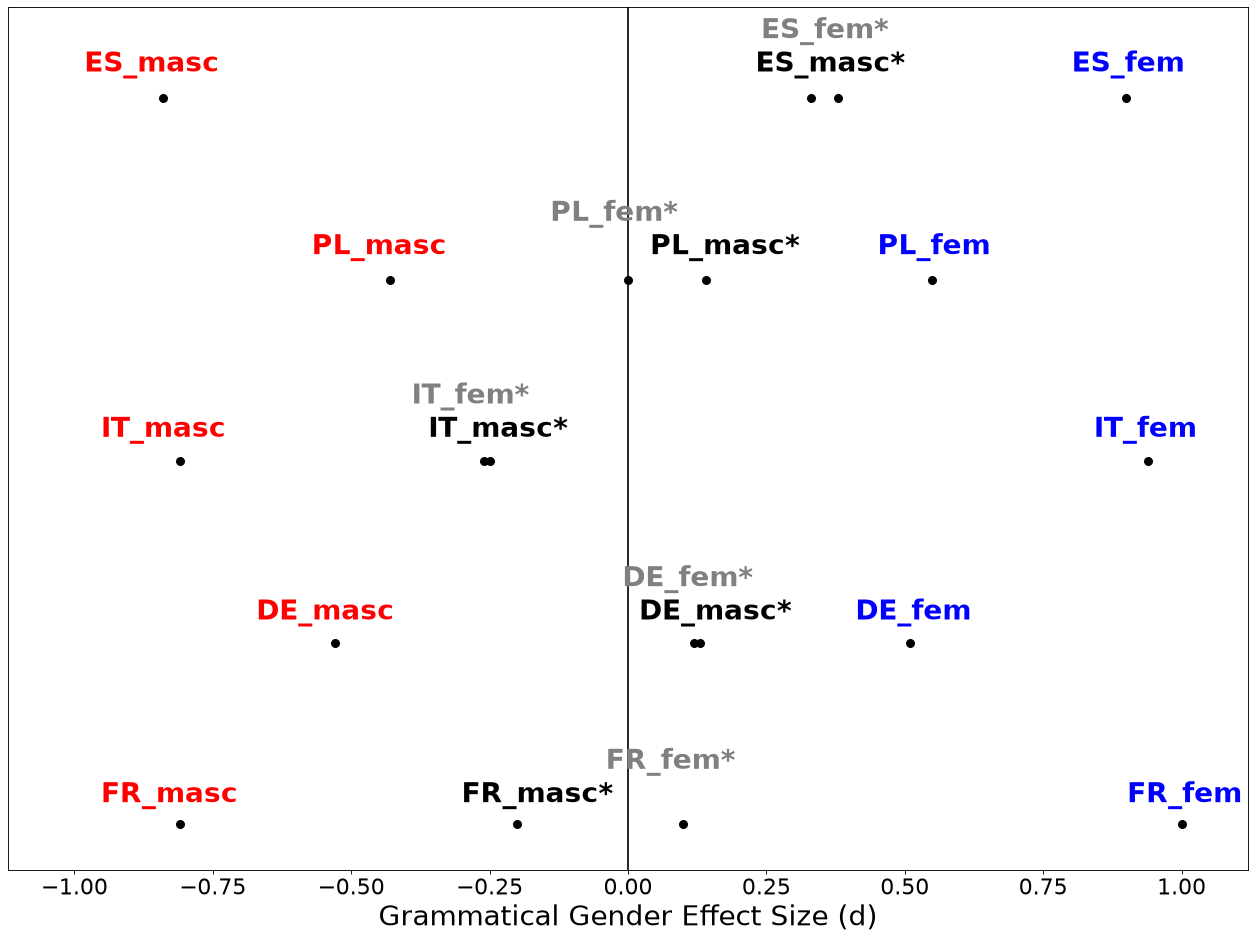

In [57]:
my_scores = [[-0.81, -0.20, 1, 0.1], [-0.53, 0.12, 0.51, 0.13], [-0.81, -0.26, 0.94, -0.25], [-0.43,0.14, 0.55, 0], [-0.84, 0.33, 0.90, 0.38]]
all_groups = [["FR_masc","FR_fem"], 
             ["DE_masc","DE_fem"],
             ["IT_masc","IT_fem"],
             ["PL_masc","PL_fem"],
             ["ES_masc","ES_fem"]]

import matplotlib.pyplot as plt

x_coords = []
y_coords = []
for i in range(5):
    y_coords.append(i)
    y_coords.append(i)
    y_coords.append(i)
    y_coords.append(i)
word_labels = []
count = 0
for scores, words in zip(my_scores, all_groups):
    # first word is masculine before
    x_coords.append(scores[0])
    # second word is masculine after
    x_coords.append(scores[1])
    # third word is feminine before
    x_coords.append(scores[2])
    # fourth word is feminine after
    x_coords.append(scores[3])
    
    word_labels.append(words[0])
    word_labels.append(words[0]+'*')
    word_labels.append(words[1])
    word_labels.append(words[1]+'*')
    
# display scatter plot
fig=plt.figure(figsize=(20, 14), dpi=80)
#ax = plt.subplot(111,aspect = 'equal')
#plt.subplots_adjust(left=0, bottom=0, right=1, top=1, wspace=0, hspace=0)
plt.scatter(x_coords, y_coords, marker='o',c='k',s=50)
for k, (label, x, y) in enumerate(zip(word_labels, x_coords, y_coords)):
    if k % 4 == 0:
        color = 'red'
        plt.annotate(label, xy=(x, y), xytext=(x-70, y+20), textcoords='offset points', fontsize=25,
                    bbox=dict(pad=5, facecolor="none", edgecolor="none"), color=color, weight='bold')
    elif k % 4 == 1:
        color = 'black'
        plt.annotate(label, xy=(x, y), xytext=(x-50, y+20), textcoords='offset points', fontsize=25,
                    bbox=dict(pad=5, facecolor="none", edgecolor="none"), color=color, weight='bold')
    elif k% 4 == 2:
        color = 'blue'
        plt.annotate(label, xy=(x, y), xytext=(x-50, y+20), textcoords='offset points', fontsize=25,
                    bbox=dict(pad=5, facecolor="none", edgecolor="none"), color=color, weight='bold')
        continue
    elif k%4 == 3:
        color = 'gray'
        plt.annotate(label, xy=(x, y), xytext=(x-70, y+50), textcoords='offset points', fontsize=25,
                    bbox=dict(pad=5, facecolor="none", edgecolor="none"), color=color, weight='bold')
        continue
  

plt.xlim(-1 - 0.12, 1 + 0.12)
plt.ylim(0 - 0.25, 4 + 0.5)
plt.tick_params(labelsize=20)
plt.xlabel('Grammatical Gender Effect Size (d)', fontsize=25)
    
#plt.axhline(y=0, color='k')
plt.axvline(x=0, color='k')
plt.yticks([])
plt.margins(tight=True)

plt.show()

fig.savefig('sc-gg.pdf',bbox_inches='tight')


In [58]:

import json as _json
_want = _json.load(open("dump_words.json"))
_train = sorted(set(sum(map(list, shortened_3000), [])))
_ws = [w for w in _want if w in my_word2id]
_ids = [my_word2id[w] for w in _ws]
_am = [w for w in man if w in my_word2id]; _af = [w for w in wom if w in my_word2id]
np.savez("vectors.npz", words=np.array(_ws), before=my_embeddings[_ids],
         after=WEAT_gender_removed_embeddings_2[_ids],
         man=np.array(_am), wom=np.array(_af),
         man_before=my_embeddings[[my_word2id[w] for w in _am]],
         man_after=WEAT_gender_removed_embeddings_2[[my_word2id[w] for w in _am]],
         wom_before=my_embeddings[[my_word2id[w] for w in _af]],
         wom_after=WEAT_gender_removed_embeddings_2[[my_word2id[w] for w in _af]],
         train_words=np.array(_train), num_iter=num_iter,
         final_acc=clf_3000_after.score(X_rest_after, y_rest_after))
print("dumped", len(_ws), "of", len(_want), "words;", len(_am), "+", len(_af), "attributes")


dumped 1270 of 1276 words; 8 + 8 attributes
